WISCONSIN BREAST CANCER DATASET
Dataset Shape: 569 rows, 32 columns

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980     

/tmp/ipykernel_2311/3043114335.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="diagnosis", palette=["#2b5c8f", "#d95f02"])


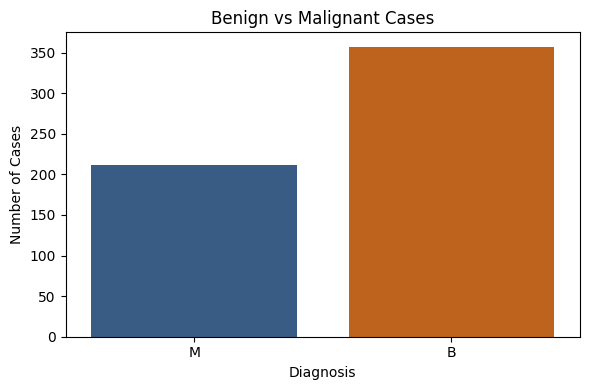


DATA SPLIT
Training samples: 455
Testing samples:  114

EVALUATION METRICS (Threshold = 0.50)
Accuracy:   0.9737 (97.37%)
Precision:  0.9756
Recall:     0.9524
F1-Score:   0.9639
ROC-AUC:    0.9954


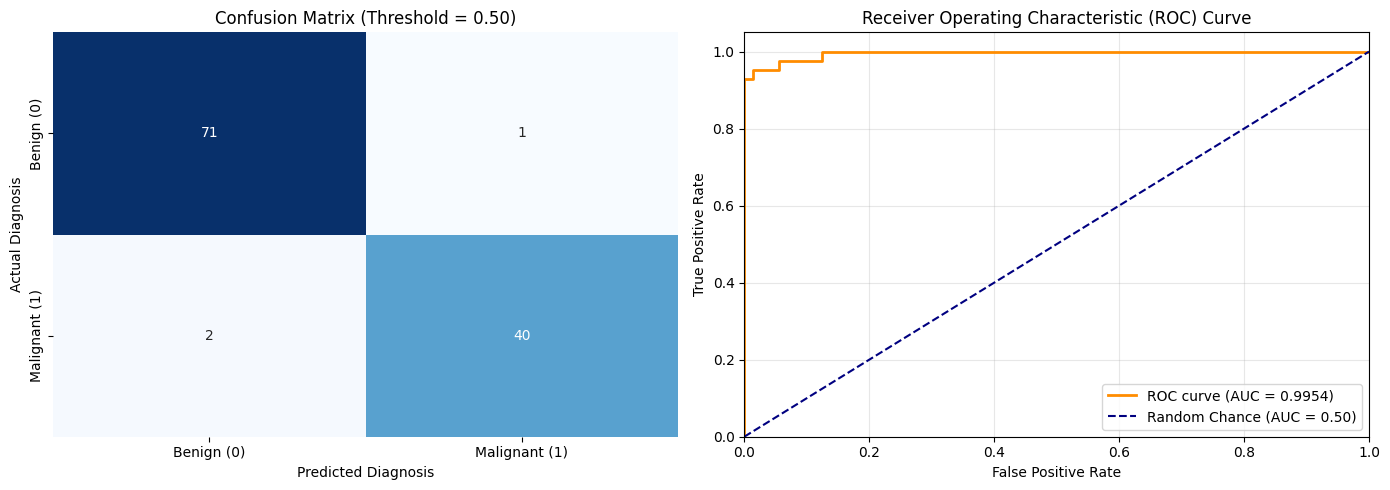


TOP 5 PREDICTORS OF MALIGNANCY (Positive Coefficients)
            Feature  Coefficient
      texture_worst     1.466159
          radius_se     1.309001
     symmetry_worst     1.076920
concave_points_mean     0.969977
    concavity_worst     0.936887

TOP 5 PREDICTORS OF BENIGNITY (Negative Coefficients)
             Feature  Coefficient
         symmetry_se    -0.371838
          texture_se    -0.372516
    compactness_mean    -0.531902
fractal_dimension_se    -0.587421
      compactness_se    -0.960795


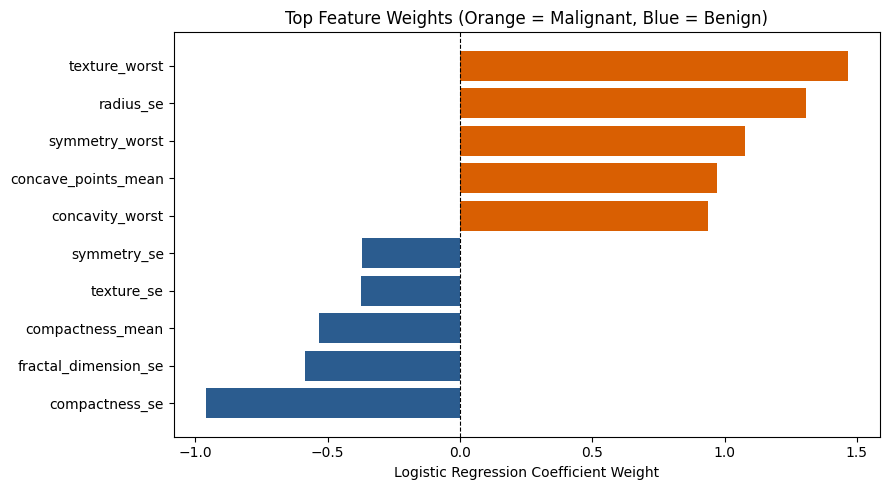


CLINICAL RISK THRESHOLD EVALUATION (Threshold = 0.3)
True Positives  (TP - Malignant detected): 40
False Negatives (FN - Missed Malignant):   2
False Positives (FP - False Alarms):       2
True Negatives  (TN - Correctly Benign):   70
Clinical Recall (Sensitivity):             0.9524 (95.24%)


In [2]:
# ==============================================================================
# Wisconsin Breast Cancer Detection using Logistic Regression
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# 1. Load Wisconsin Breast Cancer Dataset Directly from UCI
# ==============================================================================
data_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "breast-cancer-wisconsin/wdbc.data"
)

feature_names = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

column_names = ["id", "diagnosis"] + feature_names

df = pd.read_csv(data_url, header=None, names=column_names)

# ==============================================================================
# 2. Display Dataset Information
# ==============================================================================
print("=" * 70)
print("WISCONSIN BREAST CANCER DATASET")
print("=" * 70)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nFirst 5 rows:")
print(df.head())

# ==============================================================================
# 3. Display Class Distribution
# ==============================================================================
counts = df["diagnosis"].value_counts()

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)
print(f"Benign (B):    {counts.get('B', 0)}")
print(f"Malignant (M): {counts.get('M', 0)}")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="diagnosis", palette=["#2b5c8f", "#d95f02"])
plt.title("Benign vs Malignant Cases", fontsize=12)
plt.xlabel("Diagnosis", fontsize=10)
plt.ylabel("Number of Cases", fontsize=10)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. Data Preprocessing
# ==============================================================================
# Drop non-predictive ID column
df_clean = df.drop(columns=["id"])

# Map target: Benign (B) = 0, Malignant (M) = 1
df_clean["diagnosis"] = df_clean["diagnosis"].map({"B": 0, "M": 1})

# Separate features (X) and target (y)
X = df_clean.drop(columns=["diagnosis"])
y = df_clean["diagnosis"]

# ==============================================================================
# 5. Train-Test Split (80% Train, 20% Test)
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\n" + "=" * 70)
print("DATA SPLIT")
print("=" * 70)
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

# ==============================================================================
# 6. Feature Scaling (StandardScaler)
# ==============================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 7. Model Training (Balanced Logistic Regression)
# ==============================================================================
model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)
model.fit(X_train_scaled, y_train)

# ==============================================================================
# 8. Predictions & Probability Estimation
# ==============================================================================
# Positive class: Malignant (1)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Default decision threshold = 0.5
threshold_default = 0.5
y_pred_default = (y_pred_proba >= threshold_default).astype(int)

# ==============================================================================
# 9. Performance Metrics (Default Threshold = 0.5)
# ==============================================================================
accuracy = accuracy_score(y_test, y_pred_default)
precision = precision_score(y_test, y_pred_default, zero_division=0)
recall = recall_score(y_test, y_pred_default, zero_division=0)
f1 = f1_score(y_test, y_pred_default, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\n" + "=" * 70)
print("EVALUATION METRICS (Threshold = 0.50)")
print("=" * 70)
print(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-Score:   {f1:.4f}")
print(f"ROC-AUC:    {roc_auc:.4f}")
print("=" * 70)

# ==============================================================================
# 10. Confusion Matrix & ROC Curve Plots
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
cm_default = confusion_matrix(y_test, y_pred_default)
labels = ["Benign (0)", "Malignant (1)"]

sns.heatmap(
    cm_default,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=False,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Threshold = 0.50)", fontsize=12)
axes[0].set_xlabel("Predicted Diagnosis", fontsize=10)
axes[0].set_ylabel("Actual Diagnosis", fontsize=10)

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Chance (AUC = 0.50)")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate", fontsize=10)
axes[1].set_ylabel("True Positive Rate", fontsize=10)
axes[1].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ==============================================================================
# 11. Most Influential Features (Coefficients Analysis)
# ==============================================================================
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

print("\n" + "=" * 70)
print("TOP 5 PREDICTORS OF MALIGNANCY (Positive Coefficients)")
print("=" * 70)
print(coef_df.head(5).to_string(index=False))

print("\n" + "=" * 70)
print("TOP 5 PREDICTORS OF BENIGNITY (Negative Coefficients)")
print("=" * 70)
print(coef_df.tail(5).to_string(index=False))

# Plot Top 10 Coefficients by Absolute Impact
top_features = pd.concat([coef_df.head(5), coef_df.tail(5)]).sort_values(by="Coefficient")

plt.figure(figsize=(9, 5))
colors = ["#2b5c8f" if c < 0 else "#d95f02" for c in top_features["Coefficient"]]
plt.barh(top_features["Feature"], top_features["Coefficient"], color=colors)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Top Feature Weights (Orange = Malignant, Blue = Benign)", fontsize=12)
plt.xlabel("Logistic Regression Coefficient Weight", fontsize=10)
plt.tight_layout()
plt.show()

# ==============================================================================
# 12. Clinical Threshold Evaluation (Lower Threshold to Catch False Negatives)
# ==============================================================================
clinical_threshold = 0.30
y_pred_clinical = (y_pred_proba >= clinical_threshold).astype(int)
cm_clinical = confusion_matrix(y_test, y_pred_clinical)

tn_c, fp_c, fn_c, tp_c = cm_clinical.ravel()
recall_clinical = recall_score(y_test, y_pred_clinical)

print("\n" + "=" * 70)
print(f"CLINICAL RISK THRESHOLD EVALUATION (Threshold = {clinical_threshold})")
print("=" * 70)
print(f"True Positives  (TP - Malignant detected): {tp_c}")
print(f"False Negatives (FN - Missed Malignant):   {fn_c}")
print(f"False Positives (FP - False Alarms):       {fp_c}")
print(f"True Negatives  (TN - Correctly Benign):   {tn_c}")
print(f"Clinical Recall (Sensitivity):             {recall_clinical:.4f} ({recall_clinical * 100:.2f}%)")
print("=" * 70)